INTERNATIONAL FOOTBALL (SOCCER) MATCHES ANALYSIS  
In this portfolio we'll analyze the key factors that help football teams to win a game.  
This analysis includes football games played between 2023-09-08 and 2026-04-14 of many competences of national and international games, even games between National Football Teams.

In [19]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

In [21]:
plt.style.use('dark_background')
sns.set_palette(['#00d8ff', '#ff6600', '#aaaaaa']) 
plt.rcParams['figure.facecolor'] = '#121212'
plt.rcParams['axes.facecolor'] = '#121212'
plt.rcParams['axes.grid'] = False 
plt.rcParams['axes.edgecolor'] = '#333333'

In [22]:
df1 = pd.read_csv('football_dataset.csv', low_memory = False)

In [23]:
conexion = sqlite3.connect(':memory:')
df1.to_sql('football_data', conexion, index=False)

16688

In [24]:
df1.date.head(10)

0       August 24, 2024
1       August 17, 2024
2        April 01, 2025
3        April 08, 2025
4     December 22, 2024
5      January 03, 2025
6    September 21, 2024
7    September 15, 2024
8        April 19, 2025
9        April 25, 2025
Name: date, dtype: object

In [25]:
df1['date'] = pd.to_datetime(df1['date'])

In [26]:
recent_match = df1[df1['date'] == df1['date'].max()][['date', 'home_team', 'home_goals', 'away_team', 'away_goals']]
print(recent_match)
oldest_match = df1[df1['date'] == df1['date'].min()][['date', 'home_team', 'home_goals', 'away_team', 'away_goals']]
print(oldest_match)

          date        home_team  home_goals        away_team  away_goals
337 2026-04-14            Lanus         1.0         Banfield         0.0
387 2026-04-14  Velez Sarsfield         1.0  Central Cordoba         0.0
            date  home_team  home_goals  away_team  away_goals
15845 2023-09-08  Argentina         1.0    Ecuador         0.0
16121 2023-09-08   Colombia         1.0  Venezuela         0.0
16608 2023-09-08   Paraguay         0.0       Peru         0.0


In [27]:
df1.kickoff_time.head()

0    05:00 PM
1    04:00 PM
2    09:00 PM
3    09:00 PM
4    06:00 PM
Name: kickoff_time, dtype: object

In [28]:
df1['kickoff_time'] = pd.to_datetime(df1['kickoff_time'], format="%H:%M %p")

In [29]:
df1.kickoff_time.dtypes

dtype('<M8[ns]')

In [30]:
df1['home_goals'].isnull().sum()

2

In [31]:
df1 = df1.dropna(subset=['home_goals', 'away_goals'])

In [32]:
print(df1['home_goals'].isnull().sum())
print(df1['away_goals'].isnull().sum())

0
0


In [33]:
df1['away_goals'].head()

0    0.0
1    0.0
2    0.0
3    1.0
4    1.0
Name: away_goals, dtype: float64

In [34]:
df1['home_goals'] = df1['home_goals'].astype(int)
df1['away_goals'] = df1['away_goals'].astype(int)

In [35]:
df1['home_goals'].head()

0    2
1    1
2    1
3    0
4    6
Name: home_goals, dtype: int32

In [36]:
possible_duplicated = df1.duplicated(subset=['date', 'home_team', 'away_team']).sum()
print(f"Duplicated matches: {possible_duplicated}")

Duplicated matches: 0


In [37]:
df1 = df1.drop_duplicates(subset=['date', 'home_team', 'away_team'])

In [38]:
import numpy as np

In [39]:
df1.result.describe()

count     16686
unique        3
top           H
freq       7457
Name: result, dtype: object

In [40]:
result_percentage = df1['result'].value_counts(normalize=True) * 100
result_percentage

result
H    44.690159
A    30.648448
D    24.661393
Name: proportion, dtype: float64

In [41]:
home_goals_avg = df1['home_goals'].mean()
away_goals_avg = df1['away_goals'].mean()

print("--- Average of Goals by Match ---")
print(f"Goals Scored by Home Team: {home_goals_avg:.2f}")
print(f"Goals Scored by Away Team: {away_goals_avg:.2f}")

--- Average of Goals by Match ---
Goals Scored by Home Team: 1.53
Goals Scored by Away Team: 1.22


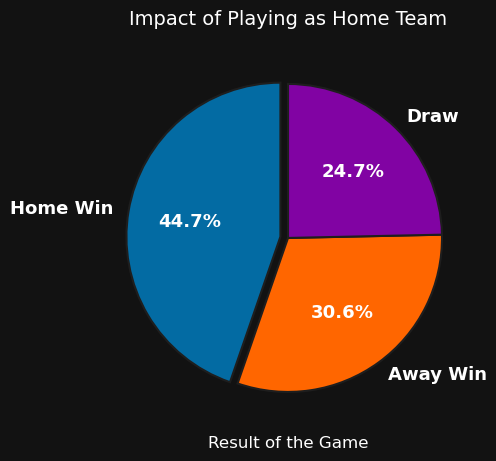

In [42]:
fig, ax = plt.subplots(figsize=(9, 5))

categories = ['Home Win', 'Away Win', 'Draw']
values = [result_percentage['H'], result_percentage['A'], result_percentage['D']]
colors = ['#036ba3', '#ff6600', '#8103a3']  

separation = (0.05, 0, 0) 

ax.pie(values, 
       labels=categories, 
       colors=colors, 
       autopct='%1.1f%%',
       startangle=90,    
       explode=separation,
       textprops={'color': 'white', 'fontsize': 13, 'fontweight': 'bold'},
       wedgeprops={'edgecolor': '#1e1e1e', 'linewidth': 1.5})

ax.set_title('Impact of Playing as Home Team', color='white', fontsize=14, pad=15)
ax.set_xlabel('Result of the Game', color='white', fontsize=12)

plt.show()

With this chart we can see that home teams win more than away, also, we noticed that the average goals scored by home teams are higher than away teams.   
So, the home team has more probabilities to win a football match, most of the public supports the team and also the footballers know the pitch better than the away team.  
Note: It is necessary to clarify that some matches like the World Cup or Eurocup, a team is considered as "home" or "away" to shuffle which team will wear their Home colors kit, so, those teams such as National Teams are not really home or away because the location is neutral.

Now, let's visualize the most goalscore teams, it means, the Top 10 of teams with the best goal average during the last years.

In [45]:
QUERY1 = """
WITH Join_matches AS (
    SELECT
        home_team AS team,
        home_goals AS goals_favor,
        away_goals AS goals_against
    FROM football_data
    
    UNION ALL
    
    SELECT
        away_team AS team,
        away_goals AS goals_favor,
        home_goals AS goals_against
    FROM football_data
)

SELECT
    team,
    AVG(goals_favor) AS scored_goals_avg
FROM Join_matches
GROUP BY team
HAVING COUNT(*) >= 30
ORDER BY scored_goals_avg DESC
LIMIT 10;
"""
df_best_attackers = pd.read_sql_query(QUERY1, conexion)
print(df_best_attackers.head(12))

            team  scored_goals_avg
0  Bayern Munich          3.043478
1            PSV          2.698795
2      Barcelona          2.693878
3        Al-Sadd          2.674419
4       Al Hilal          2.656716
5       Al Nassr          2.557377
6            PSG          2.489796
7    Inter Miami          2.386364
8    Galatasaray          2.279070
9       Dortmund          2.120879


Now, let's see the best teams at defending, the ones that rarely receive a goal by match.

In [47]:
QUERY2 = """
WITH Join_matches AS (
    SELECT
        home_team AS team,
        home_goals AS goals_favor,
        away_goals AS goals_against
    FROM football_data
    
    UNION ALL
    
    SELECT
        away_team AS team,
        away_goals AS goals_favor,
        home_goals AS goals_against
    FROM football_data
)

SELECT
    team,
    AVG(goals_against) AS received_goals_avg
FROM Join_matches
GROUP BY team
HAVING COUNT(*) >= 30
ORDER BY received_goals_avg ASC
LIMIT 10;
"""
df_best_defenders = pd.read_sql_query(QUERY2, conexion)
print(df_best_defenders.head(12))

            team  received_goals_avg
0      Tokushima            0.650000
1       Coritiba            0.714286
2            ZED            0.716981
3        Arsenal            0.755319
4       Pyramids            0.774194
5        Zamalek            0.811321
6    Flamengo RJ            0.826923
7  Novorizontino            0.842105
8       El Gouna            0.867925
9       Criciuma            0.868421


In [48]:
df1['home_possession_pct'].head()

0     NaN
1     NaN
2    68.0
3    64.0
4    59.0
Name: home_possession_pct, dtype: float64

In this point, let's analyze the percentage of home teams that dominate the game, it means with a high possession and passes rate that obtain the victory in a football match.  
So, we'll choose home teams with a possession pct bigger than 60% and with more passes than its rival team.

In [50]:
QUERY6 = """
    SELECT (SUM(CASE WHEN result = 'H' THEN 1 ELSE 0 END) * 100) / COUNT(*) AS win_rate_pct
    FROM football_data 
    WHERE home_possession_pct >= 60 AND home_passes_total > away_passes_total
"""
home_high_pos = pd.read_sql_query(QUERY6, conexion)
print(home_high_pos .head(12))

   win_rate_pct
0            44


44% of teams with this conditions won the game.

Let's try the opposite side, home teams with a possession lower than 41% and less total passes than its rival.

In [53]:
QUERY8 = """
    SELECT (SUM(CASE WHEN result = 'H' THEN 1 ELSE 0 END) * 100) / COUNT(*) AS win_rate_pct
    FROM football_data 
    WHERE home_possession_pct < 41 AND home_passes_total < away_passes_total
"""
home_low_pos = pd.read_sql_query(QUERY8, conexion)
print(home_low_pos .head(12))

   win_rate_pct
0            42


42% of home teams with this conditions won the game, very similar to the percetage of dominant teams, so we can conclude that having a "dominion" of the game is almost like being defensive when we look at the result of the match. So, why do these teams win when they have two different styles of philosophy of games?  
Well, the fact they are playing at home is very important, but, we'll answer that question later.

We'll analyze the away teams that are more offensive than the home team with the same conditions we defined before.

In [56]:
QUERY9 = """
    SELECT (SUM(CASE WHEN result = 'A' THEN 1 ELSE 0 END) * 100) / COUNT(*) AS win_rate_pct
    FROM football_data 
    WHERE away_possession_pct >= 60 < 41 AND away_passes_total < home_passes_total
"""
away_high_pos = pd.read_sql_query(QUERY9, conexion)
print(away_high_pos .head(12))

   win_rate_pct
0            30


30% of away teams with a high possession and passes rate won the game.

In [58]:
QUERY10 = """
    SELECT (SUM(CASE WHEN result = 'A' THEN 1 ELSE 0 END) * 100) / COUNT(*) AS win_rate_pct
    FROM football_data 
    WHERE away_possession_pct <= 40 AND away_passes_total < home_passes_total
"""
away_low_pos = pd.read_sql_query(QUERY10, conexion)
print(away_low_pos .head(12))

   win_rate_pct
0            28


On the other hand, defensive away teams only win the 28% of their matches, so we can affirm that home teams has more advantages, we could see it in the first graph of this portfolio.   
Note: it is important to clarify we selected matches where the data about possession and total passes were available.

Then, it's time to create a correlation between some variables to know their impact in the match for a team, this first correlation and heatmap will analyze some characteristics to make a heatmap easier for understading with little variables: goals, xg, shots_total and touches in the opposite box.  
Later, we'll analyze more variables to be more specifc.

In [61]:
first_correlation = df1[['home_goals','home_xg', 'home_shots_total', 'home_shots_on_target', 'home_touches_opp_box']].corr()

This first correlation will be about Home Teams and the variables mentioned above.

In [63]:
first_correlation

,home_goals,home_xg,home_shots_total,home_shots_on_target,home_touches_opp_box
home_goals,1.000000,0.587359,0.301722,0.574661,0.274597
home_xg,0.587359,1.000000,0.659774,0.668530,0.621765
home_shots_total,0.301722,0.659774,1.000000,0.677864,0.769743
home_shots_on_target,0.574661,0.668530,0.677864,1.000000,0.548590
home_touches_opp_box,0.274597,0.621765,0.769743,0.548590,1.000000


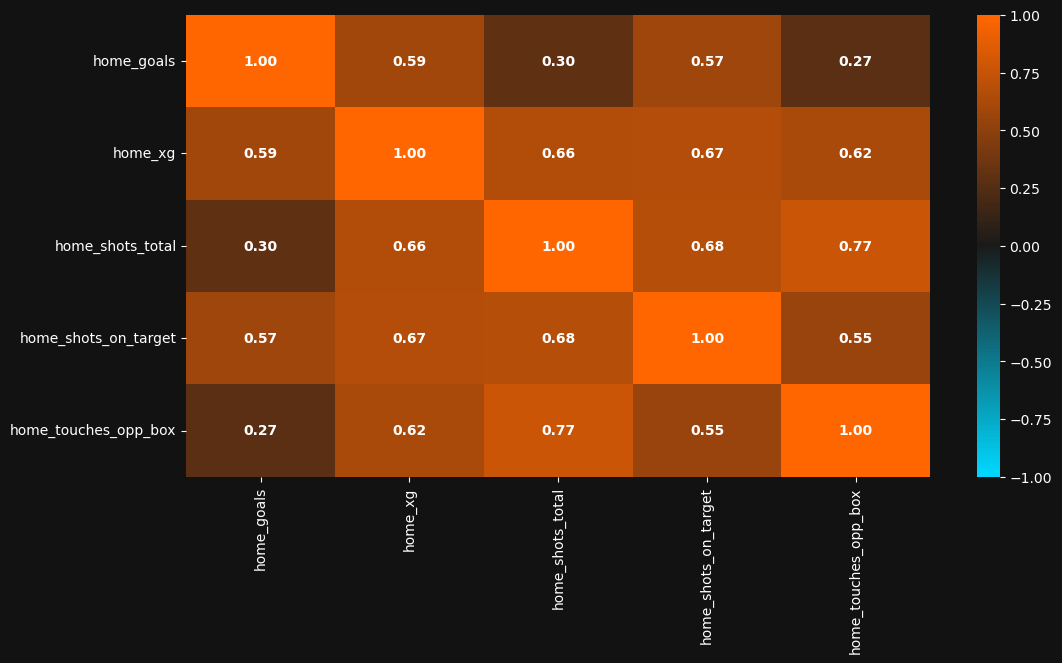

In [64]:
from matplotlib.colors import LinearSegmentedColormap

neon_colors = ['#00d8ff', '#1a1a1a', '#ff6600']
neon_map = LinearSegmentedColormap.from_list('portfolio_style', neon_colors)

plt.figure(figsize=(12,6))
sns.heatmap(
    first_correlation,
    annot=True,
    fmt=".2f",
    cmap=neon_map,
    cbar=True,
    vmin=-1, 
    vmax=1, 
    linecolor='#1a1a1a',      
    annot_kws={"color": "white", "weight": "bold", "size": 10}
)
plt.show()

-In fact, there is a strong relation between home_xg, home_touches_opp_box, and home_shots_total and it makes sense because teams that play in the rival box area have more probabilities to shot on rival'g goal.  
-However, total_shots have a weak correlation with real goals, on the contrary home shots on target have a better correlation, a team can shot many times on a game and have more chances to score, but, the goalkeeper can also save shots.  
-Also, teams with more expectation of goals normally have a strong correlation with total shots.

In [66]:
away_correlation = df1[['away_goals','away_xg', 'away_shots_total', 'away_shots_on_target', 'away_touches_opp_box']].corr()
away_correlation

,away_goals,away_xg,away_shots_total,away_shots_on_target,away_touches_opp_box
away_goals,1.000000,0.596425,0.327329,0.591409,0.303141
away_xg,0.596425,1.000000,0.672594,0.674402,0.628379
away_shots_total,0.327329,0.672594,1.000000,0.681680,0.766658
away_shots_on_target,0.591409,0.674402,0.681680,1.000000,0.554516
away_touches_opp_box,0.303141,0.628379,0.766658,0.554516,1.000000


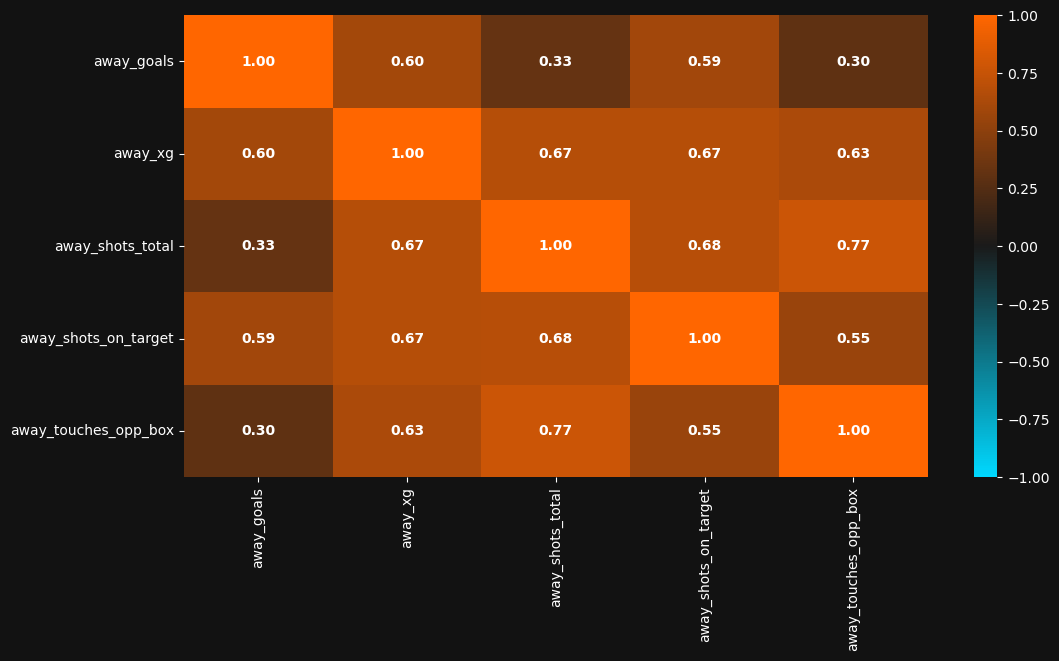

In [67]:
plt.figure(figsize=(12,6))
sns.heatmap(
    away_correlation,
    annot=True,
    fmt=".2f",
    cmap=neon_map,
    cbar=True,
    vmin=-1, 
    vmax=1, 
    linecolor='#1a1a1a',      
    annot_kws={"color": "white", "weight": "bold", "size": 10}
)
plt.show()

-On the other hand, we can see again a strong relation between home_xg, home_touches_opp_box, and home_shots_total. So, it makes that the correlations of home and away teams are similar with some little differences, for example, some values of the Away Heatmap are higher than the Home Heatmap.  
-However, total_shots have a weak correlation with real goals, on the contrary home shots on target have a better correlation, a team can shot many times on a game and have more chances to score, but, the goalkeeper can also save shots.  
-Also, teams with more expectation of goals normally have a strong correlation with total shots.

Now, in this point, we'll analyze deeper other factors that make a team win: passes_total, possession, touches_opp_box, shots_on_target, shots_total, and xg. So, for this analysis we'll use scatter plots to find possible patterns and trends between the mentioned factors with the result and the quantity of goals scored by a team. Also, we won't distinguish home or away teams to create a general analysis.

In [70]:
QUERY11 = """
WITH Join_effectiveness AS (
        SELECT
            CASE 
            WHEN home_goals > away_goals THEN 'Win'
            WHEN home_goals < away_goals THEN 'Loss'
            ELSE 'Draw' 
        END AS match_result,
        home_team AS team,
        home_goals AS goals,
        home_xg AS xg,
        home_shots_total AS shots_total,
        home_shots_on_target AS shots_on_target,
        home_touches_opp_box AS touches_opp_box,
        home_possession_pct AS possession,
        home_passes_total AS passes_total
    FROM football_data
    
    UNION ALL
    
    SELECT
        CASE 
            WHEN away_goals > home_goals THEN 'Win'
            WHEN away_goals < home_goals THEN 'Loss'
            ELSE 'Draw' 
        END AS match_result,
        away_team AS team,
        away_goals AS goals,
        away_xg AS xg,
        away_shots_total AS shots_total,
        away_shots_on_target AS shots_on_target,
        away_touches_opp_box AS touches_opp_box,
        away_possession_pct AS possession,
        away_passes_total AS passes_total
    FROM football_data
)

SELECT
    team, match_result, goals, passes_total, possession, touches_opp_box, shots_on_target, shots_total, xg,
    CASE WHEN shots_total = 0 THEN 0 ELSE goals * 1.0 / shots_total END AS goals_shots_effectiveness,
    CASE WHEN shots_total = 0 THEN 0 ELSE shots_on_target * 1.0 / shots_total END AS shots_effectiveness,
    CASE WHEN possession = 0 THEN 0 ELSE xg * 1.0 / possession END AS expected_goals_possession,
    CASE WHEN possession = 0 THEN 0 ELSE goals * 1.0 / possession END AS goal_possession,
    CASE WHEN possession = 0 THEN 0 ELSE shots_on_target * 1.0 / possession END AS shots_possession
FROM Join_effectiveness
WHERE passes_total AND possession AND touches_opp_box AND touches_opp_box AND shots_on_target AND shots_total AND xg AND goals IS NOT NULL;
"""
effectiveness = pd.read_sql_query(QUERY11, conexion)
print(effectiveness.head(12))

                       team match_result  goals  passes_total  possession  \
0                   Al Ahly          Win    1.0         527.0        68.0   
1         Al-Hilal Omdurman         Loss    0.0         460.0        64.0   
2       CR Belouizdad (Alg)          Win    1.0         361.0        53.0   
3                   Al Ahly         Draw    1.0         362.0        40.0   
4             Al Ahly (Egy)         Loss    1.0         591.0        60.0   
5     Stade d'Abidjan (Ivo)         Loss    1.0         369.0        43.0   
6             Mazembe (Drc)          Win    4.0         364.0        50.0   
7   Al-Hilal Omdurman (Sud)         Draw    1.0         423.0        53.0   
8   Al-Hilal Omdurman (Sud)         Loss    0.0         396.0        51.0   
9           FAR Rabat (Mar)          Win    2.0         507.0        60.0   
10            Maniema (Drc)         Loss    1.0         255.0        39.0   
11    Raja Casablanca (Mar)          Win    1.0         408.0        57.0   

We will distinguish between Volume (passes_total, possession, touches_opp_box, shots_on_target, and shots_total) and Effectiveness (goals, shots on target, match result, and in some cases expected goals) to see possible patterns and explain how volume impacts on effectiveness.  
With this, we can confirm and/or deny some statements of football, for example, "A team does not to attack so much to win a match, but just to score a goal" or "The more a team has a ball, the more probabilities a team can score".   
First analysis: Total Shots vs Goals.

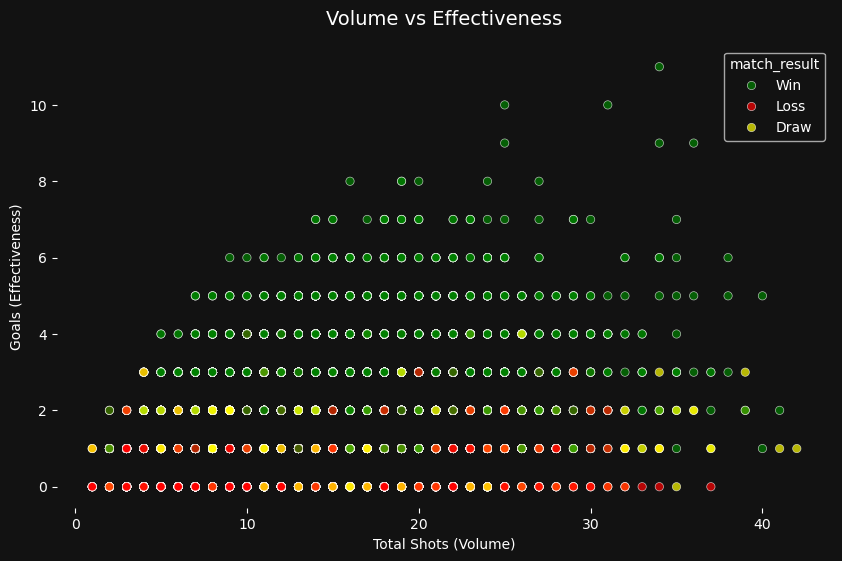

In [72]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='shots_total', 
                y='goals', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Total Shots (Volume)', color='white')
ax.set_ylabel('Goals (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

We can see that more shots don't mean more goals, in fact, it is necessary to shot on target, but these are total shots, shots on target and off target.  
We can see matches where a team scored 3 goals and shot more than 20 times but lost the game, they were effective on attacking but not at defending.

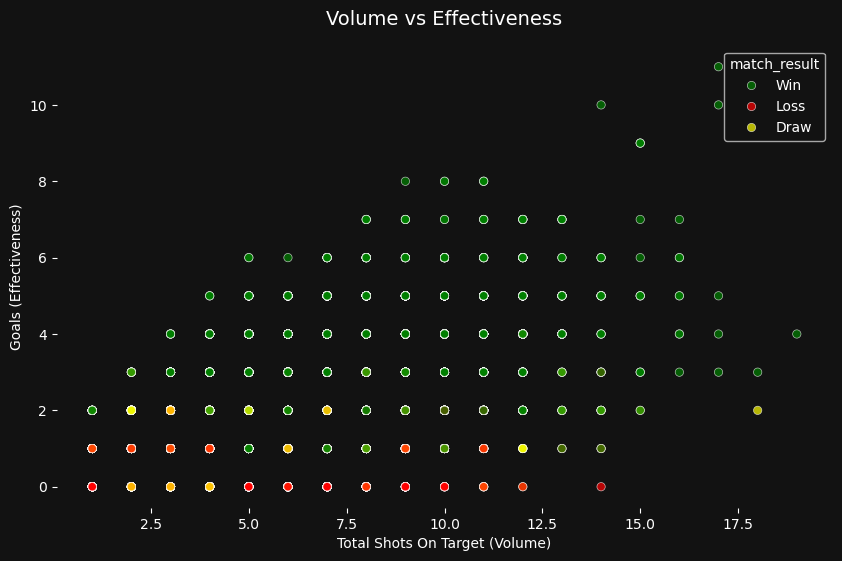

In [74]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='shots_on_target', 
                y='goals', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Total Shots On Target (Volume)', color='white')
ax.set_ylabel('Goals (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

In this graph, we can notice that many teams are effective on shooting on target, but it does mean they will score a goal or win a match, obviously there are more probabilities on scoring more goals with more shots on target, but we must not forget the role of the goalkeeper that saves shots from the rival team.  
Nevertheless, it is important to notice that with more goals, more probabilities to win a match (well, that's how a team wins) and for that it is necesssary to shot on target, the main question is how to defeat the goalkeeper of the rival.

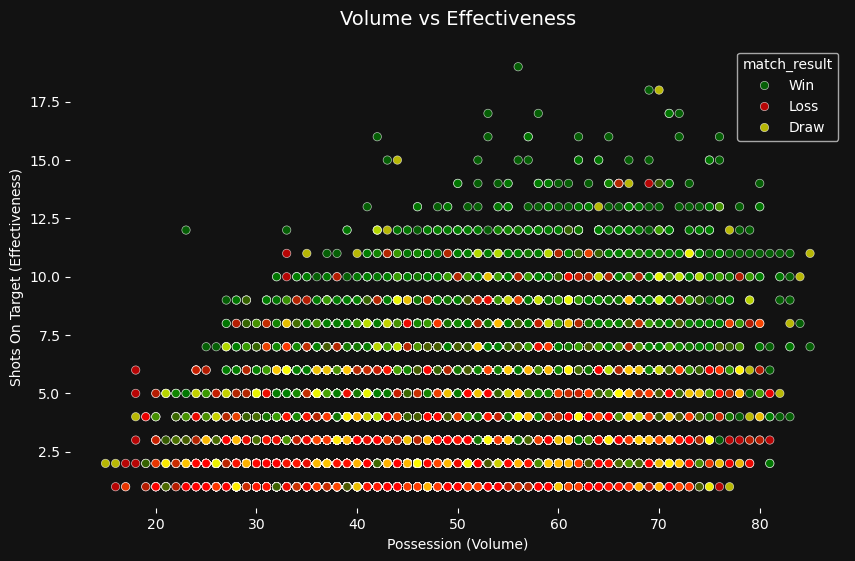

In [76]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='possession', 
                y='shots_on_target', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Possession (Volume)', color='white')
ax.set_ylabel('Shots On Target (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

In this graph, we can prove that having a great possession is a key factor to shot on target because the team has the ball, however, there are teams that have more than 70% of possession and didn't shot various times, in fact, some of them lost the game as we can notice in the graph, for example, we can see teams that shot more than 12 times with a high possession and lost the game because their shots were saved by the goalkeeper or another player or saved by the wood of the goal.

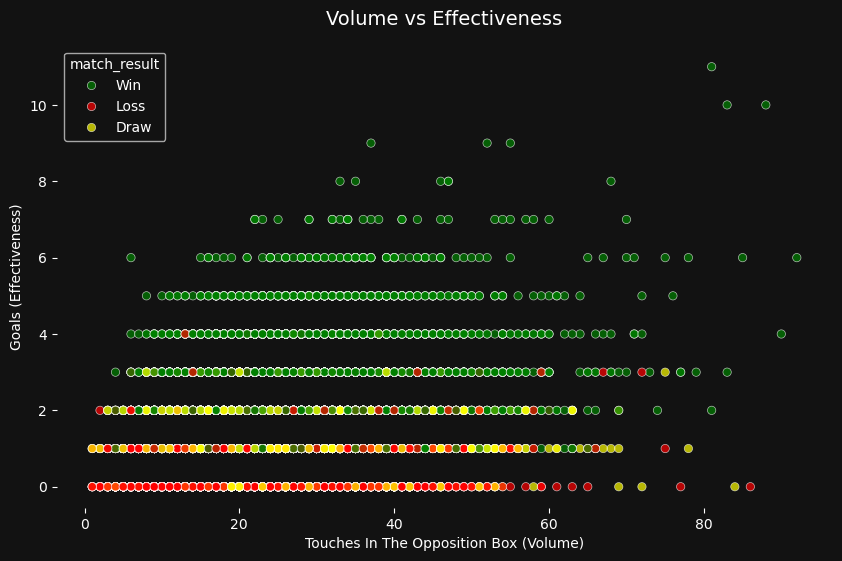

In [78]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='touches_opp_box', 
                y='goals', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Touches In The Opposition Box (Volume)', color='white')
ax.set_ylabel('Goals (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

Now, in this plot, we can notice that more touches in the opposition box doesn't mean more goals, in fact, more touches in the opposition box have a high positive correlation with shots on target, however, some teams might pass the ball inside the rival box but they don't shoot. 

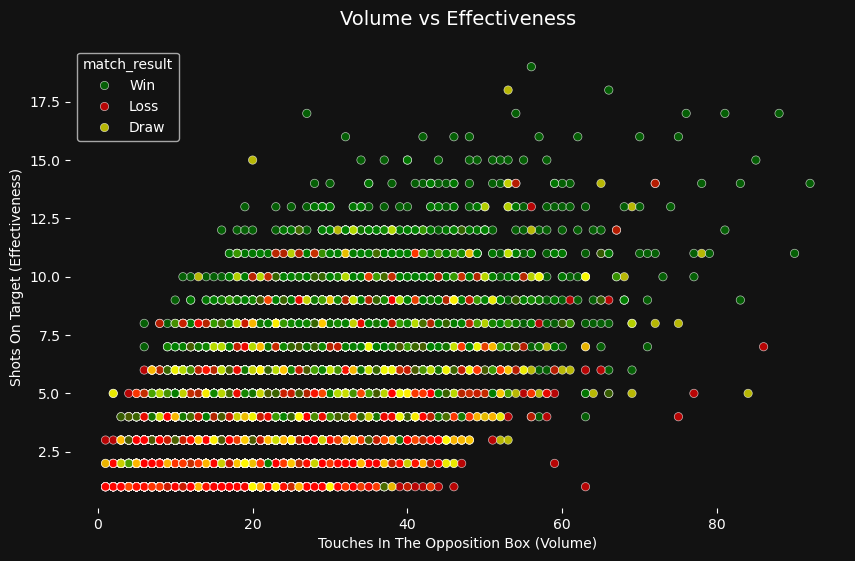

In [80]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='touches_opp_box', 
                y='shots_on_target', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Touches In The Opposition Box (Volume)', color='white')
ax.set_ylabel('Shots On Target (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

So, we analyzed the relation between shots on target and touches in the opposition box, so, it is possible to see that some teams might have the same quantity of touches inside the opposition box, but, some teams shot more on target than others and that's why they score more goals and probably win the game, so touching the ball inside the opposition box is useful when the team shoots on target. 

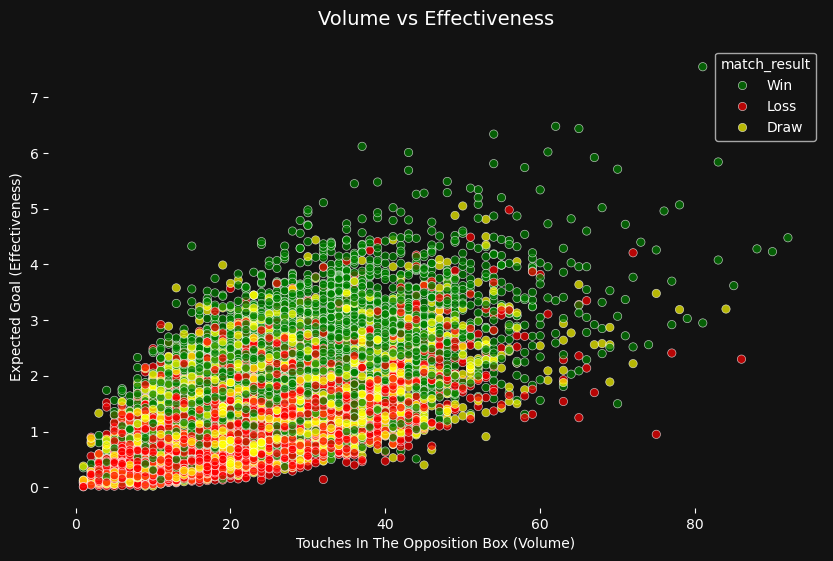

In [82]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='touches_opp_box', 
                y='xg', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Touches In The Opposition Box (Volume)', color='white')
ax.set_ylabel('Expected Goal (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

In this case, we can notice the correlation between expected goal and the touches in opposition box is more complicated because we can see positive and negative results, nevertheless, we might notice that teams with more than 2 expected goals tends to win the game compared with teams with less than 2 expected goals.

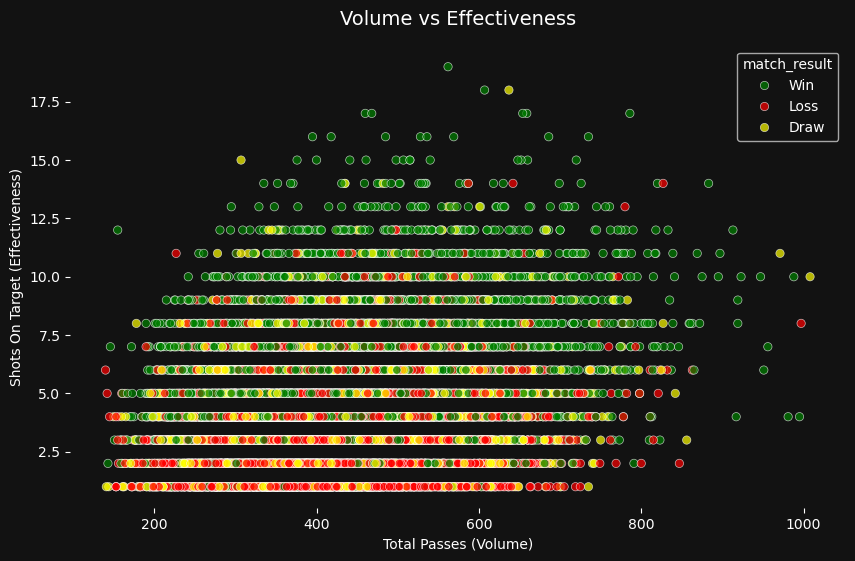

In [84]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='passes_total', 
                y='shots_on_target', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Total Passes (Volume)', color='white')
ax.set_ylabel('Shots On Target (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

Now, in this chart we can conclude the same with the correlation between shots on target and total passes is similar with the previous correlation of possession, a team might pass the ball more than its rival but if they don't shoot on target, they will not probably score a goal.

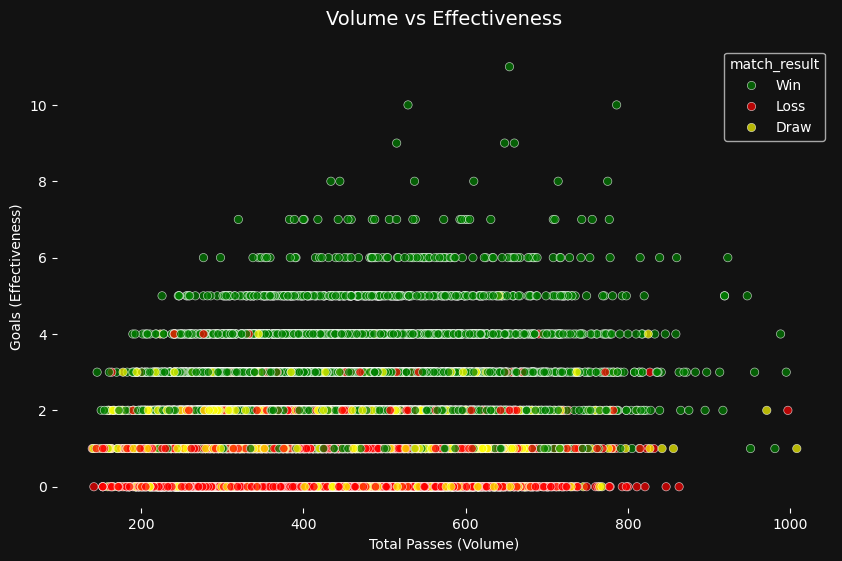

In [86]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=effectiveness, 
                x='passes_total', 
                y='goals', 
                hue='match_result', 
                palette=['green', 'red', 'yellow'], 
                alpha=0.7, 
                ax=ax)

ax.set_title('Volume vs Effectiveness', color='white', fontsize=14, pad=15)
ax.set_xlabel('Total Passes (Volume)', color='white')
ax.set_ylabel('Goals (Effectiveness)', color='white')
sns.despine(left=True, bottom=True)

plt.show()

Now, considering the previous chart, more passes don't mean more goals, total passes are key when the team takes advantages of it and shoots on target to score more goals, that's why in fact some people say that football is a pragmatic sport: a team doesn't need to touch the ball many times or having the ball all the time, teams must be effective by shooting on target and have more probabilities to score goals.

In [88]:
QUERY12 = """
    WITH Join_formation AS (
        SELECT
        CASE 
            WHEN home_goals > away_goals THEN 'Win'
            WHEN home_goals < away_goals THEN 'Loss'
            ELSE 'Draw'
            END AS match_result,
            home_team AS team,
            home_goals AS goals,
            home_formation AS formation,
            home_team_rating AS rating
    FROM football_data
    
    UNION ALL
    
    SELECT
        CASE 
            WHEN away_goals > home_goals THEN 'Win'
            WHEN away_goals < home_goals THEN 'Loss'
            ELSE 'Draw' 
        END AS match_result,
        away_team AS team,
        away_goals AS goals,
        away_formation AS formation,
        away_team_rating AS rating
    FROM football_data
)

SELECT
    team, goals, match_result, formation
FROM Join_formation
WHERE formation IS NOT NULL
"""
formation = pd.read_sql_query(QUERY12, conexion)
print(formation.head(6))

                  team  goals match_result formation
0              Al Ahly    1.0          Win   4-2-3-1
1    Al-Hilal Omdurman    0.0         Loss   4-2-3-1
2        Al Ahly (Egy)    6.0          Win   4-2-3-1
3  CR Belouizdad (Alg)    1.0          Win     4-4-2
4    Mamelodi Sundowns    0.0         Draw   4-2-3-1
5              Al Ahly    1.0         Draw   3-4-2-1


In [89]:
formation.formation.value_counts()

formation
4-2-3-1    10130
4-3-3       6014
4-4-2       3978
3-4-2-1     2856
3-5-2       1937
4-1-4-1     1305
3-4-3       1289
5-3-2        985
5-4-1        760
3-4-1-2      743
4-5-1        277
4-3-1-2      276
3-1-4-2      274
3-3-2-2      244
4-4-1-1      240
3-5-1-1      183
4-1-2-3      178
4-3-2-1      177
4-2-1-3      153
4-1-3-2      148
4-1-2-1       73
3-3-1-3       64
4-2-2-2       54
3-2-4-1       23
5-2-3         15
3-3-3-1       11
5-3-1-1        6
4-2-4          5
3-2-3-2        4
2-3-2-3        1
5-2-2-1        1
Name: count, dtype: int64

<Figure size 1200x600 with 0 Axes>

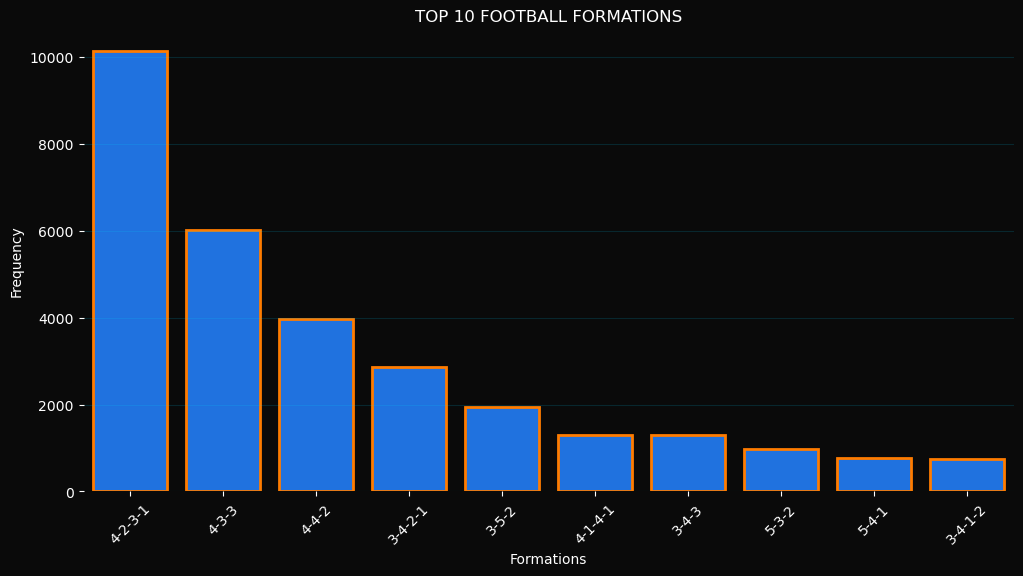

In [90]:
plt.figure(figsize=(12,6))
top_formations = formation['formation'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(12,6))
fig.patch.set_facecolor('#0a0a0a')
ax.set_facecolor('#0a0a0a')

sns.barplot(
    x=top_formations.index,
    y=top_formations.values,
    color='#006dff',
    edgecolor='#ff7c00',
    linewidth=2,
    ax=ax
)
plt.title('TOP 10 FOOTBALL FORMATIONS')
plt.xlabel('Formations') 
plt.ylabel('Frequency') 
plt.xticks(rotation=45) 
plt.grid(axis='y', color='#00d2ff',alpha=0.15)
sns.despine(left=True, bottom=True)
plt.show()

In this plot, we analyze the most popular football formations, 4-2-3-1 is the most popular, but we need to understand that formations are not fixed and teams can rotate or move player on the pitch according to their tactics, for example, 4-2-3-1 is a versatil formation because a team can rotate quickly to 4-3-3 or 4-4-2, these formations attempt to have a balance in all the lines of the team, defense, midfielders and strikes, on the other side, formations with a defense of 3 players such as 3-4-2-1, 3-5-2, 3-4-1-2 and 3-4-3 try to cover the middle part of the pitch with more players, but they may become weaker on the side because the midfielders on the side part of the pitch work also like backs, so they have more physical fatigue.

In [92]:
df1.home_xg

0         NaN
1         NaN
2        0.77
3        0.36
4         NaN
         ... 
16683     NaN
16684     NaN
16685     NaN
16686     NaN
16687    1.17
Name: home_xg, Length: 16686, dtype: float64

In [93]:
df1.home_xg.isna().sum()

3279

In [94]:
df1['home_xg_diff'] = df1['home_goals'] - df1['home_xg']
df1['away_xg_diff'] = df1['away_goals'] - df1['away_xg']


In [95]:
df1[['home_team','home_xg_diff']].head(12)

,home_team,home_xg_diff
0,Jwaneng Galaxy (Bot),NaN
1,African Stars (Nam),NaN
2,Al Ahly,0.23
3,Al-Hilal Omdurman,-0.36
4,Al Ahly (Egy),NaN
5,CR Belouizdad (Alg),-0.08
6,Al Ahly (Egy),NaN
7,Gor Mahia (Ken),NaN
8,Mamelodi Sundowns,-0.15
9,Al Ahly,-0.06


In [96]:
df1[['away_team','away_xg_diff']].head(12)

,away_team,away_xg_diff
0,African Stars (Nam),NaN
1,Jwaneng Galaxy (Bot),NaN
2,Al-Hilal Omdurman,-0.16
3,Al Ahly,0.09
4,CR Belouizdad (Alg),NaN
5,Al Ahly (Egy),-0.41
6,Gor Mahia (Ken),NaN
7,Al Ahly (Egy),NaN
8,Al Ahly,-0.52
9,Mamelodi Sundowns,0.73


In [97]:
df_xg = df1.dropna(subset=['home_team','home_xg','home_goals','away_team','away_xg','away_goals','result'])

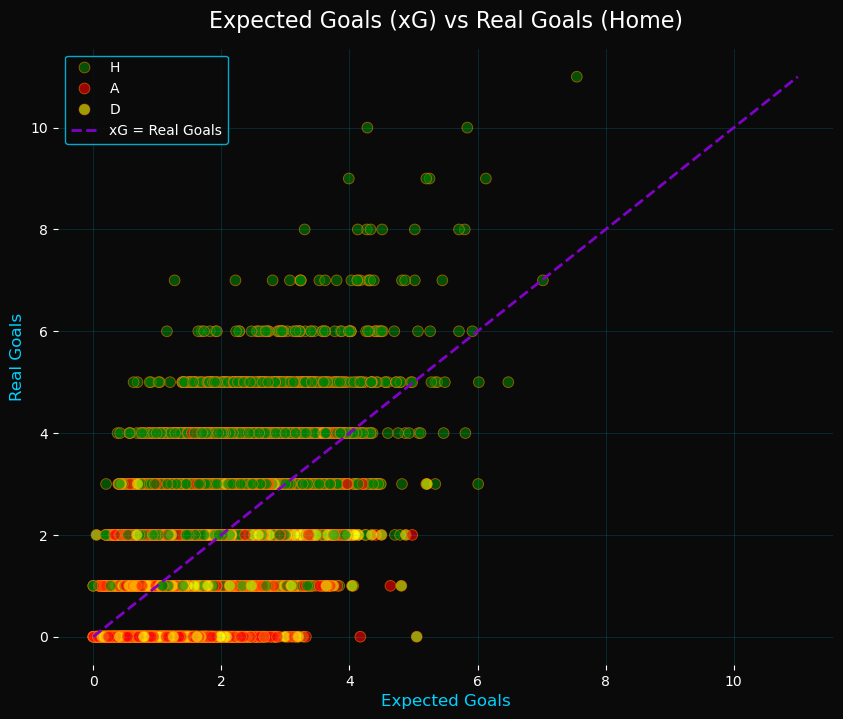

In [98]:
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('#0a0a0a')
ax.set_facecolor('#0a0a0a')

sns.scatterplot(
    data=df_xg,
    x='home_xg',
    y='home_goals',
    hue='result',
    palette=['green', 'red', 'yellow'],
    edgecolor='#ff7c00',
    s=60,
    alpha=0.6,
    ax=ax
)

# Línea de referencia (Expectativa = Realidad)
max_val = max(df_xg['home_xg'].max(), df_xg['home_goals'].max())
ax.plot([0, max_val], [0, max_val], color='#7f02c7', linestyle='--', linewidth=2, label='xG = Real Goals')

plt.title('Expected Goals (xG) vs Real Goals (Home)', fontsize=16, color='white', pad=15)
plt.xlabel('Expected Goals', fontsize=12, color='#00d2ff')
plt.ylabel('Real Goals', fontsize=12, color='#00d2ff')
plt.legend(facecolor='#0a0a0a', edgecolor='#00d2ff', labelcolor='white')
plt.grid(color='#00d2ff', alpha=0.15)

sns.despine(left=True, bottom=True)
plt.show()

-The purple dashed line represents scenarios where the Expected Goals perfectly match the actual goals scored. Data points above this line indicate highly clinical performances—teams scoring more than statistically expected. On the other hand, points below the line suggest poor finishing or outstanding saves by the opposition's goalkeeper.  
-While there is an obvious positive trend between xG and real goals, the significant vertical spread of the data points shows that football is not an exact science. Generating a high xG value does not automatically guarantee a high scoreline, highlighting the critical difference between creating chances and actually converting them.

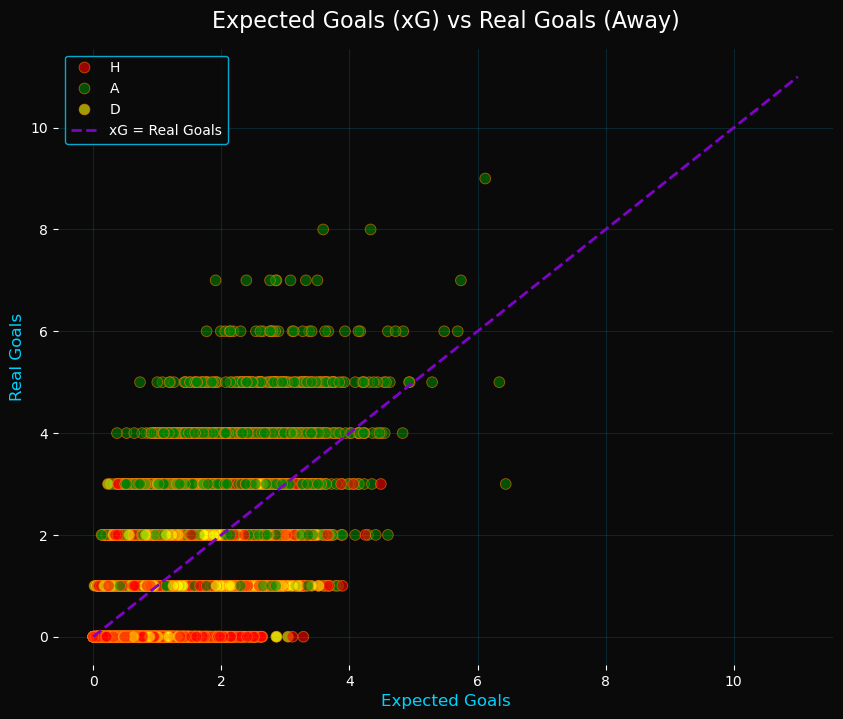

In [100]:
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('#0a0a0a')
ax.set_facecolor('#0a0a0a')

sns.scatterplot(
    data=df_xg,
    x='away_xg',
    y='away_goals',
    hue='result',
    palette=['red', 'green', 'yellow'],
    edgecolor='#ff7c00',
    s=60,
    alpha=0.6,
    ax=ax
)

# Línea de referencia (Expectativa = Realidad)
max_val = max(df_xg['home_xg'].max(), df_xg['home_goals'].max())
ax.plot([0, max_val], [0, max_val], color='#7f02c7', linestyle='--', linewidth=2, label='xG = Real Goals')

plt.title('Expected Goals (xG) vs Real Goals (Away)', fontsize=16, color='white', pad=15)
plt.xlabel('Expected Goals', fontsize=12, color='#00d2ff')
plt.ylabel('Real Goals', fontsize=12, color='#00d2ff')
plt.legend(facecolor='#0a0a0a', edgecolor='#00d2ff', labelcolor='white')
plt.grid(color='#00d2ff', alpha=0.15)

sns.despine(left=True, bottom=True)
plt.show()

-Many of the green dots (Away wins) sit significantly above the purple dashed line. This suggests that winning on the road often requires teams to be highly clinical, overperforming their Expected Goals (xG) to secure a victory.  
-Look at the extreme outliers where away teams scored 6 to 8 real goals despite having an xG between 2 and 4. These performances highlight that successful away strategies often rely on punishing the opponent's mistakes and converting low-probability chances, usually through counter-attacks.

In [102]:
QUERY14 = """
WITH Join_performance AS (
        SELECT
            CASE 
            WHEN home_goals > away_goals THEN 3
            WHEN home_goals < away_goals THEN 0
            ELSE 1
        END AS match_point,
        home_team AS team,
        home_goals AS goals,
        home_team_rating AS rating,
        home_xg AS xg,
        home_shots_total AS shots_total,
        home_shots_on_target AS shots_on_target,
        home_touches_opp_box AS touches_opp_box,
        home_possession_pct AS possession
    FROM football_data
    
    UNION ALL
    
    SELECT
        CASE 
            WHEN away_goals > home_goals THEN 3
            WHEN away_goals < home_goals THEN 0
            ELSE 1
        END AS match_point,
        away_team AS team,
        away_goals AS goals,
        away_team_rating AS rating,
        away_xg AS xg,
        away_shots_total AS shots_total,
        away_shots_on_target AS shots_on_target,
        away_touches_opp_box AS touches_opp_box,
        away_possession_pct AS possession
    FROM football_data
)

SELECT
    team, match_point, goals, rating, possession, touches_opp_box, shots_on_target, shots_total, xg 
FROM Join_performance
WHERE possession AND rating AND touches_opp_box AND 
shots_on_target AND shots_total AND xg IS NOT NULL;
"""
performance1 = pd.read_sql_query(QUERY14, conexion)
print(performance1.head(12))

                       team  match_point  goals  rating  possession  \
0                   Al Ahly            3    1.0     6.9        68.0   
1         Al-Hilal Omdurman            0    0.0     6.5        64.0   
2       CR Belouizdad (Alg)            3    1.0     6.6        53.0   
3                   Al Ahly            1    1.0     6.8        40.0   
4             Al Ahly (Egy)            0    1.0     5.5        60.0   
5     Stade d'Abidjan (Ivo)            0    1.0     6.9        43.0   
6             Mazembe (Drc)            3    4.0     7.9        50.0   
7   Al-Hilal Omdurman (Sud)            1    1.0     6.1        53.0   
8   Al-Hilal Omdurman (Sud)            0    0.0     6.8        51.0   
9           FAR Rabat (Mar)            3    2.0     6.9        60.0   
10            Maniema (Drc)            0    1.0     6.4        39.0   
11    Raja Casablanca (Mar)            3    1.0     8.7        57.0   

    touches_opp_box  shots_on_target  shots_total    xg  
0              26.

In [103]:
performance_corr = performance1.corr(numeric_only=True)

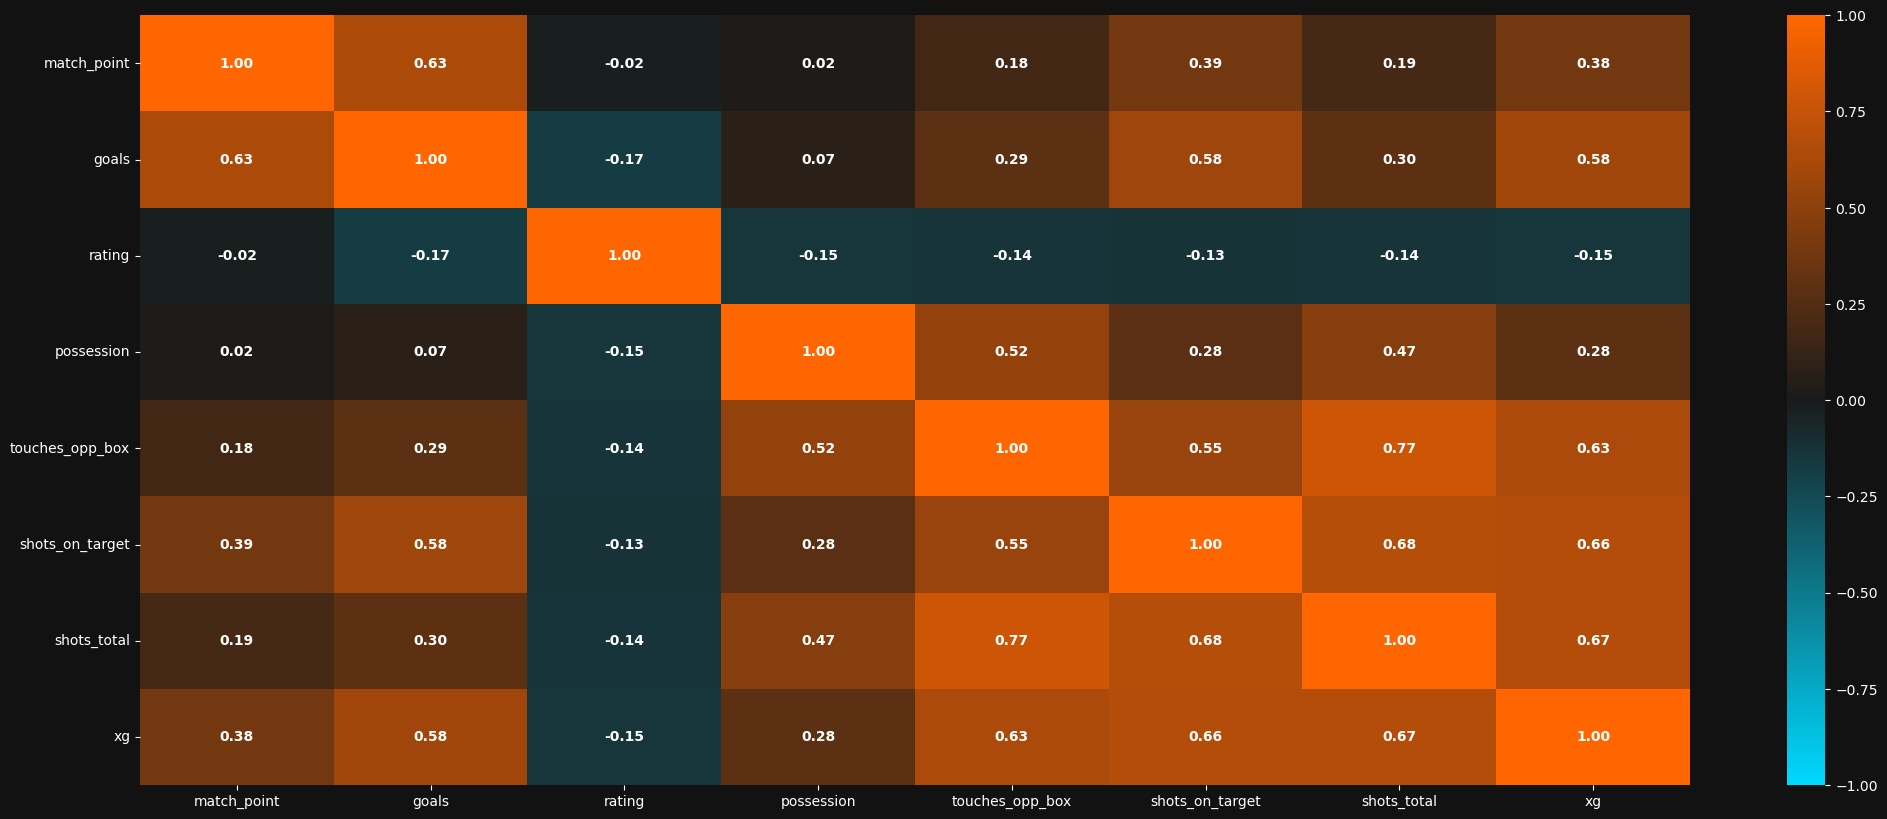

In [104]:
plt.figure(figsize=(25,10))
sns.heatmap(
    performance_corr,
    annot=True,
    fmt=".2f",
    cmap=neon_map,
    cbar=True,
    vmin=-1, 
    vmax=1, 
    linecolor='#1a1a1a',      
    annot_kws={"color": "white", "weight": "bold", "size": 10}
)
plt.show()

-Now, in this correlation matrix highlights a crucial insight in modern football analytics: possession alone does not win games. The data shows an extremely weak correlation (0.07) between ball possession and actual goals scored.  
-Instead, attacking efficiency is driven by penetration. Metrics such as touches in the opponent's box and shots on target show a strong positive correlation with Expected Goals (xG), proving that where you have the ball matters significantly more than how long you keep it.

In [105]:
QUERY15 = """
WITH Join_performance AS (
        SELECT
            CASE 
            WHEN home_goals > away_goals THEN 3
            WHEN home_goals < away_goals THEN 0
            ELSE 1
        END AS match_point,
        home_team AS team,
        home_goals AS goals,
        home_passes_total AS passes_total,
        home_shots_off_target AS shots_off_target,
        home_headed_goals AS headed_goals,
        home_corners AS corners,
        home_free_kicks AS free_kicks,
        home_passes_final_third_pct AS passes_final_third_pct
    FROM football_data
    
    UNION ALL
    
    SELECT
        CASE 
            WHEN away_goals > home_goals THEN 3
            WHEN away_goals < home_goals THEN 0
            ELSE 1
        END AS match_point,
        away_team AS team,
        away_goals AS goals,
        away_passes_total AS passes_total,
        away_shots_off_target AS shots_off_target,
        away_headed_goals AS headed_goals,
        away_corners AS corners,
        away_free_kicks AS free_kicks,
        away_passes_final_third_pct AS passes_final_third_pct
    FROM football_data
)

SELECT
    team, match_point, goals, headed_goals, corners,
    free_kicks, passes_final_third_pct 
FROM Join_performance
WHERE shots_off_target AND 
headed_goals AND corners AND
free_kicks AND passes_final_third_pct
IS NOT NULL;
"""
performance2 = pd.read_sql_query(QUERY15, conexion)
print(performance2.head(12))

                       team  match_point  goals  headed_goals  corners  \
0             Mazembe (Drc)            3    4.0           1.0      5.0   
1     Esperance Tunis (Tun)            3    4.0           1.0      7.0   
2   Mamelodi Sundowns (Rsa)            1    1.0           1.0      7.0   
3                  Pyramids            3    2.0           1.0      2.0   
4                  Pyramids            3    3.0           1.0      4.0   
5                   Al Ahly            0    2.0           1.0      7.0   
6             Al Ahly (Egy)            3    4.0           1.0     11.0   
7             Al Ahly (Egy)            3    2.0           1.0      1.0   
8            Pyramids (Egy)            3    3.0           1.0      4.0   
9     Esperance Tunis (Tun)            3    2.0           1.0      5.0   
10              Simba (Tan)            1    2.0           2.0      4.0   
11     Young Africans (Tan)            3    3.0           1.0      7.0   

    free_kicks  passes_final_third_pc

In [106]:
performance2_corr = performance2.corr(numeric_only=True)

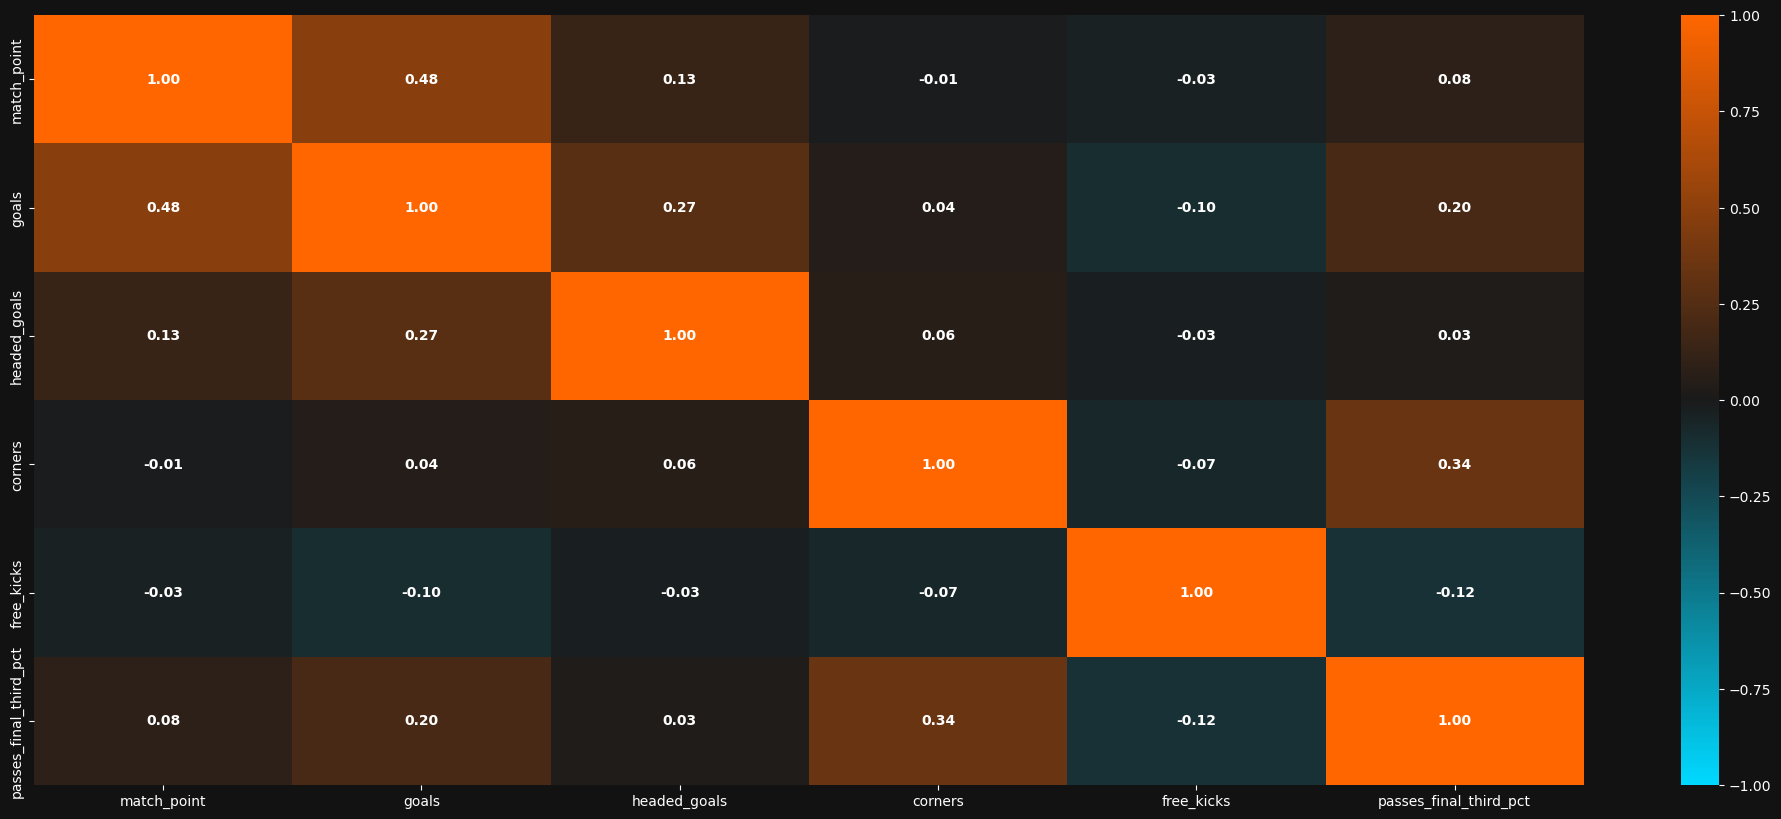

In [107]:
plt.figure(figsize=(25,10))
sns.heatmap(
    performance2_corr,
    annot=True,
    fmt=".2f",
    cmap=neon_map,
    cbar=True,
    vmin=-1, 
    vmax=1, 
    linecolor='#1a1a1a',      
    annot_kws={"color": "white", "weight": "bold", "size": 10}
)
plt.show()

-When analyzing specific match events, the matrix reveals that relying on set-pieces is not a sustainable winning strategy. Corners and free kicks show minimal to zero correlation with goals or match points.  
-Conversely, a higher percentage of passes completed in the final third (passes_final_third_pct) shows a stronger relationship with overall attacking threat, reinforcing that open-play progression is a more reliable indicator of a team's offensive success.

In [108]:
conditions_home_winner = (
    (df1['result'] == 'H') & 
    (df1['home_possession_pct'] < df1['away_possession_pct']) &
    (df1['home_passes_total'] < df1['away_passes_total']) & 
    (df1['home_xg'] < df1['away_xg']) &
    (df1['home_xg'] < df1['away_xg']) &
    (df1['home_shots_on_target'] < df1['away_shots_on_target'])
)
defensive_matches_home = df1[conditions_home_winner]

print(defensive_matches_home[['home_team', 'away_team', 'home_goals', 'away_goals', 'home_possession_pct', 'away_possession_pct', 'home_xg', 'away_xg','home_shots_on_target','away_shots_on_target']].head(20))


            home_team      away_team  home_goals  away_goals  \
484   Velez Sarsfield    River Plate           1           0   
502           Avenida    Ypiranga FC           3           0   
518       EC Sao Jose     SER Caxias           1           0   
575            Gremio    Atletico-MG           2           1   
627             Bahia        Vitoria           2           1   
693           Vitoria     Bragantino           1           0   
720             Ceara   Sport Recife           2           0   
734         Fortaleza    Corinthians           2           1   
765          Cruzeiro       Mirassol           2           1   
797         Juventude   Sport Recife           2           0   
805         Fortaleza    Flamengo RJ           1           0   
826        Fluminense      Fortaleza           2           1   
901          Mirassol          Vasco           3           2   
950       Atletico-MG  Internacional           1           0   
1012        Sao Paulo    Flamengo RJ    

In [109]:
conditions_away_winner = (
    (df1['result'] == 'A') & 
    (df1['home_possession_pct'] > df1['away_possession_pct']) &
    (df1['home_passes_total'] > df1['away_passes_total']) & 
    (df1['home_xg'] > df1['away_xg']) &
    (df1['home_shots_on_target'] > df1['away_shots_on_target'])
)
defensive_matches_away = df1[conditions_away_winner]

print(defensive_matches_away[['home_team', 'away_team', 'home_goals', 'away_goals', 'home_possession_pct', 'away_possession_pct', 'home_xg', 'away_xg','home_shots_on_target','away_shots_on_target']].head(20))


               home_team              away_team  home_goals  away_goals  \
10         Al Ahly (Egy)  Orlando Pirates (Rsa)           1           2   
119             MC Alger        Orlando Pirates           0           1   
157              Al Ahly        Esperance Tunis           2           3   
281  Rivers United (Nga)    Power Dynamos (Zam)           0           1   
348       Ind. Rivadavia       Barracas Central           1           2   
392     Newells Old Boys     Defensa y Justicia           2           3   
395   Defensa y Justicia       Talleres Cordoba           1           2   
423     Gimnasia Mendoza          Gimnasia L.P.           0           1   
478          Racing Club        Rosario Central           1           2   
550           SER Caxias               Sao Luiz           0           2   
600          Corinthians                  Bahia           1           2   
610                Bahia              Fortaleza           2           3   
651          Botafogo RJ 

In [110]:
print('Total matches won by defensive home teams:',len(defensive_matches_home)) 
print('Total matches:',len(df1))

Total matches won by defensive home teams: 328
Total matches: 16686


In [111]:
defensive_home_pct = (len(defensive_matches_home) / len(df1)) * 100
round(defensive_home_pct,2)

1.97

In [112]:
print('Total matches won by defensive away teams:',len(defensive_matches_away)) 
print('Total matches:',len(df1))

Total matches won by defensive away teams: 517
Total matches: 16686


In [113]:
defensive_away_pct = (len(defensive_matches_away) / len(df1)) * 100
round(defensive_away_pct,2)

3.1

In [114]:
defensive_winner_pct = defensive_away_pct + defensive_home_pct
round(defensive_winner_pct,2)

5.06

In [115]:
QUERY16 = """
WITH Join_cards AS (
        SELECT
            CASE 
            WHEN home_goals > away_goals THEN 'W'
            WHEN home_goals < away_goals THEN 'L'
            ELSE 'D'
        END AS match_point,
        CASE
            WHEN home_red_cards > away_red_cards THEN 'Home with more red cards'
            WHEN home_red_cards < away_red_cards THEN 'Away with more red cards'
            ELSE 'Equals'
        END AS discipline,
        home_team AS team,
        home_goals AS goals,
        home_yellow_cards AS yellow_cards,
        home_red_cards AS red_cards
    FROM football_data
    
    UNION ALL
    
    SELECT
        CASE 
            WHEN away_goals > home_goals THEN 'W'
            WHEN away_goals < home_goals THEN 'L'
            ELSE 'D'
        END AS match_point,
        CASE
            WHEN home_red_cards < away_red_cards THEN 'Away with more red cards'
            WHEN home_red_cards > away_red_cards THEN 'Home with more red cards'
            ELSE 'Equals'
            END AS discipline,
        home_team AS team,
        home_goals AS goals,
        home_yellow_cards AS yellow_cards,
        home_red_cards AS red_cards
    FROM football_data
)

SELECT team, match_point, goals, yellow_cards, red_cards, discipline FROM Join_cards
WHERE team IS NOT NULL AND match_point IS NOT NULL AND goals AND yellow_cards IS NOT NULL AND red_cards IS NOT NULL
"""
discipline = pd.read_sql_query(QUERY16, conexion)
print(discipline.head(12))

                       team match_point  goals  yellow_cards  red_cards  \
0      Jwaneng Galaxy (Bot)           W    2.0             0          0   
1       African Stars (Nam)           W    1.0             0          0   
2                   Al Ahly           W    1.0             3          0   
3             Al Ahly (Egy)           W    6.0             1          0   
4       CR Belouizdad (Alg)           W    1.0             2          0   
5             Al Ahly (Egy)           W    3.0             0          0   
6                   Al Ahly           D    1.0             1          0   
7             Al Ahly (Egy)           L    1.0             1          0   
8     Stade d'Abidjan (Ivo)           L    1.0             3          0   
9             Al Ahly (Egy)           W    4.0             2          0   
10  Al-Hilal Omdurman (Sud)           D    1.0             0          0   
11  Al-Hilal Omdurman (Sud)           W    2.0             1          0   

   discipline  
0      E

-Now, in this part we'll analyze how a red card affects a team according to the final match result, it is well known that having one player less is a real disadvatage, specially if that team is playing away. So, we will visualize how a red card can might affect a team.

In [117]:
QUERY16 = """
WITH Join_cards AS (
        SELECT
            CASE 
            WHEN home_goals > away_goals THEN 'W'
            WHEN home_goals < away_goals THEN 'L'
            ELSE 'D'
        END AS match_point,
        CASE
            WHEN home_red_cards > away_red_cards THEN 'Team with more red cards'
            WHEN home_red_cards < away_red_cards THEN 'Rival with more red cards'
            ELSE 'Equals'
        END AS discipline,
        home_team AS team,
        home_goals AS goals,
        home_yellow_cards AS yellow_cards,
        home_red_cards AS red_cards
    FROM football_data
    
    UNION ALL
    
    SELECT
        CASE 
            WHEN away_goals > home_goals THEN 'W'
            WHEN away_goals < home_goals THEN 'L'
            ELSE 'D'
        END AS match_point,
        CASE
            WHEN away_red_cards > home_red_cards THEN 'Team with more red cards'
            WHEN away_red_cards < home_red_cards THEN 'Rival with more red cards'
            ELSE 'Equals'
            END AS discipline,
        away_team AS team,
        away_goals AS goals,
        away_yellow_cards AS yellow_cards,
        away_red_cards AS red_cards
    FROM football_data
)

SELECT discipline, match_point, COUNT(*) as quantity FROM Join_cards GROUP BY discipline, match_point;
"""
discipline = pd.read_sql_query(QUERY16, conexion)
print(discipline.head(12))

                  discipline match_point  quantity
0                     Equals           D      6974
1                     Equals           L     10480
2                     Equals           W     10480
3  Rival with more red cards           D       630
4  Rival with more red cards           L       530
5  Rival with more red cards           W      1561
6   Team with more red cards           D       630
7   Team with more red cards           L      1561
8   Team with more red cards           W       530


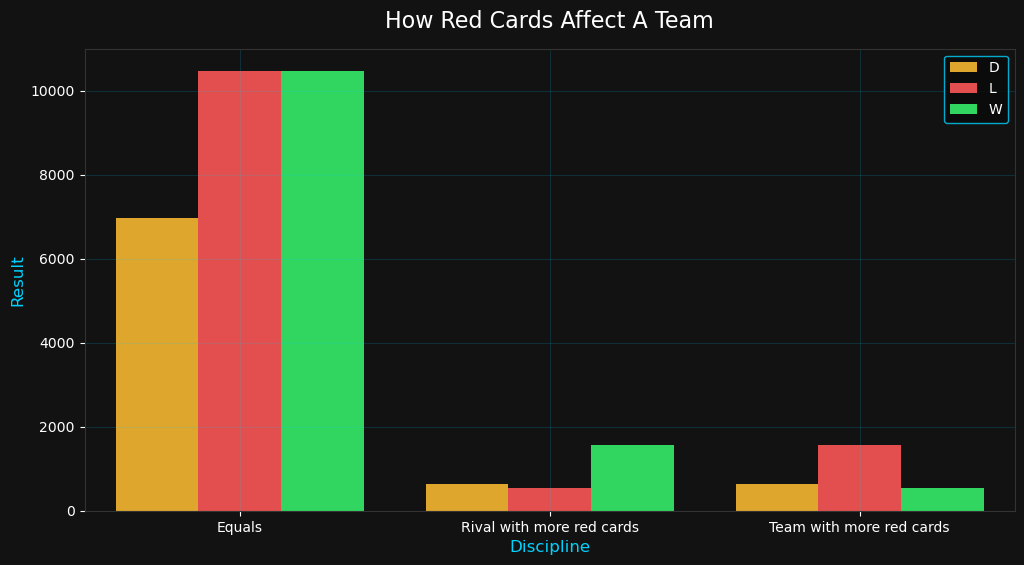

In [118]:
plt.figure(figsize=(12,6))
sns.barplot(
    data=discipline,
    x='discipline',
    y='quantity',
    hue='match_point',
    palette = ['#fcb10f','#fc3535','#16f254'],
)

plt.title('How Red Cards Affect A Team', fontsize=16, color='white', pad=15)
plt.xlabel('Discipline', fontsize=12, color='#00d2ff')
plt.ylabel('Result', fontsize=12, color='#00d2ff')
plt.legend(facecolor='#0a0a0a', edgecolor='#00d2ff', labelcolor='white')
plt.grid(color='#00d2ff', alpha=0.15)

#sns.despine(left=True, bottom=True)
plt.show()

-Well, in this graph we can notice that teams that have more players on the pitch have more chances of winning the game, meanwhile is rare a team with numerical advantage lose the game and in some cases a draw is possible when the affected team plays very defensively.  
-Now, the expected result is obvious, a team with less player than its rival have more chances of losing the game, specially if is playing away, rarely the affected team wins, maybe the localy is a key factor about that victory.  
-So, we can surely conclude a team with more red cards than its rival team have more chances on losing the game.

In [120]:
!pip install statsbombpy
from statsbombpy import sb

In [121]:
matches = sb.matches(competition_id=43, season_id=106)
matches[['match_id', 'match_date', 'home_team', 'away_team']]

,match_id,match_date,home_team,away_team
0,3857276,2022-12-01,Canada,Morocco
1,3857271,2022-11-21,England,Iran
2,3857296,2022-12-01,Croatia,Belgium
3,3857274,2022-11-25,Netherlands,Ecuador
4,3857255,2022-12-01,Japan,Spain
...,...,...,...,...
59,3857291,2022-11-23,Spain,Costa Rica
60,3857281,2022-11-27,Croatia,Canada
61,3857280,2022-12-02,Cameroon,Brazil
62,3857279,2022-11-22,France,Australia


In [122]:
df_events = sb.events(match_id=3857271)

df_passes = df_events[df_events['type'] == 'Pass'].copy()

df_shots = df_events[df_events['type'] == 'Shot'].copy()

In [123]:
print(df_passes.shape)
print(df_shots.shape)

(1093, 94)
(21, 94)


In [124]:
!pip install mplsoccer

In [125]:
from mplsoccer import Pitch

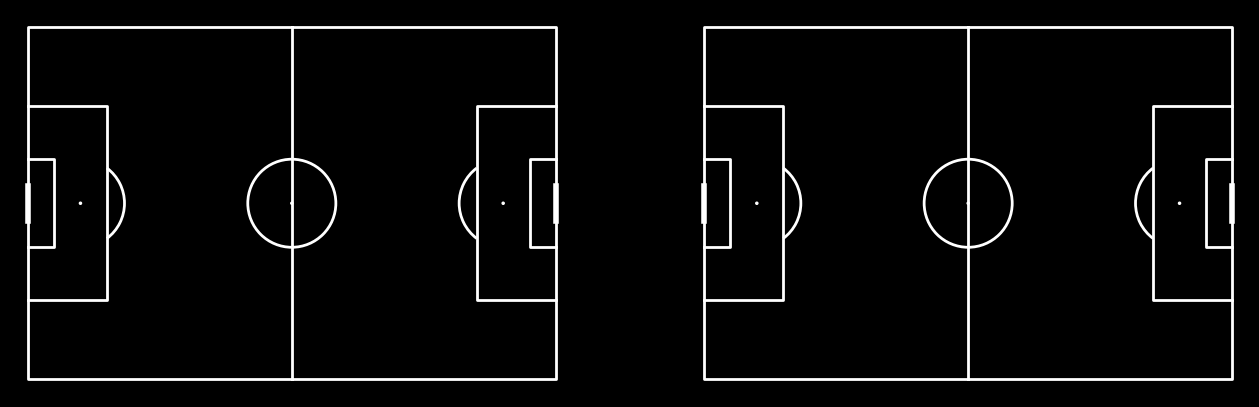

In [126]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))
fig.patch.set_facecolor('black') 
pitch = Pitch(pitch_color='black', line_color='white')

pitch.draw(ax=axs[0])
pitch.draw(ax=axs[1])

plt.show()

In [128]:
df_passes[['x', 'y']] = df_passes['location'].to_list()
df_passes[['end_x', 'end_y']] = df_passes['pass_end_location'].to_list()

In [130]:
complete_passes = df_passes[df_passes['pass_outcome'].isnull()]
failed_passes = df_passes[df_passes['pass_outcome'].notnull()]

In [132]:
df_shots[['x', 'y']] = df_shots['location'].to_list()
goals = df_shots[df_shots['shot_outcome'] == 'Goal']
missed_shots = df_shots[df_shots['shot_outcome'] != 'Goal']

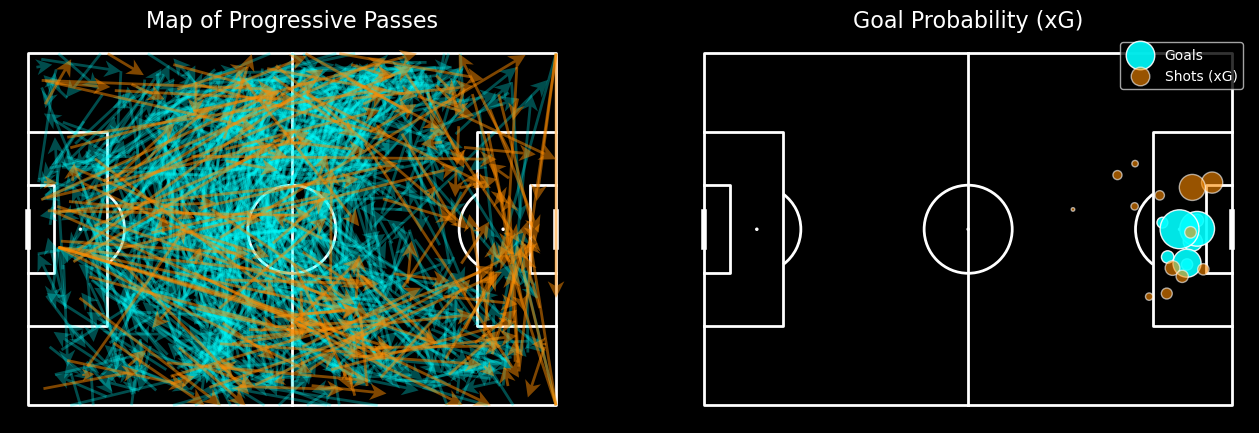

In [136]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))
fig.patch.set_facecolor('black')
pitch = Pitch(pitch_color='black', line_color='white')
pitch.draw(ax=axs[0])
pitch.draw(ax=axs[1])

pitch.arrows(complete_passes.x, complete_passes.y, 
              complete_passes.end_x, complete_passes.end_y, 
              width=2, headwidth=6, headlength=6, color='#00FFFF', ax=axs[0], alpha=0.3) #blue

pitch.arrows(failed_passes.x, failed_passes.y, 
              failed_passes.end_x, failed_passes.end_y, 
              width=2, headwidth=6, headlength=6, color='#FF8C00', ax=axs[0], alpha=0.5) #orange
axs[0].set_title('Map of Progressive Passes', color='white', fontsize=16)

pitch.scatter(goals.x, goals.y, s=goals['shot_statsbomb_xg']*1000, 
               color='#00FFFF', edgecolors='white', ax=axs[1], alpha=0.9, label='Goals')

pitch.scatter(missed_shots.x, missed_shots.y, s=missed_shots['shot_statsbomb_xg']*1000, 
               color='#FF8C00', edgecolors='white', ax=axs[1], alpha=0.6, label='Shots (xG)')
axs[1].set_title('Goal Probability (xG)', color='white', fontsize=16)
axs[1].legend(facecolor='black', labelcolor='white')

plt.savefig('analisis_tactico_portafolio.png', dpi=300, bbox_inches='tight', facecolor='black')
plt.show()

-Map of Progressive Passes: The dense network of lines illustrates the team's ability to break through defensive blocks, heavily utilizing the half-spaces and flanks to push the ball into the penalty area.   
-Goal Probability (xG): This shot map perfectly visualizes the concept of shot quality. While the team attempted several low-probability shots from outside the box (orange dots), the actual goals (cyan dots) were exclusively converted from high-xG locations deep inside the penalty area. This confirms that successful progressive passing translates into lethal finishing when chances are created in the "Golden Zone".